# Deep learning for healthcare, session 1
# From one neuron to a black box

**Question for today:** what changes, for patients and clinical teams, when we replace a model we can read with one we cannot?

We reuse the intensive care data from notebooks 01 to 03: 4,000 adult stays from the PhysioNet Challenge 2012. The prediction stays the same: **will this patient die in hospital within 7 days of admission to the intensive care unit (ICU)?**

**How to use this notebook:** run it top to bottom. Every chart is followed by a short "What this shows" box. You can follow live or just watch; medical terms are explained as we go

> **Responsible artificial intelligence (AI): five questions for all sessions.** For every model we ask the same five questions:
> 1. **What does it use?** Which information drives the output?
> 2. **How sure is it?** Are its risk numbers trustworthy?
> 3. **Who does it miss?** Which patients or groups get worse results?
> 4. **Can we explain it faithfully?** Does the explanation match what the model really does?
> 5. **Who is accountable?** Who checks it, acts on it and answers for it?

## Setup

The notebook runs locally or in Google Colab. In Colab, `torch` is already installed; locally create and activate the Conda environment in `environment.yml` as described in the README

In [1]:
# Setup: libraries, reproducibility and plot style
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(2)

plt.rcParams.update({"figure.figsize": (8, 4.5), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "font.size": 11})
NAVY, GREEN, LIME, GREY, RED = "#0b1f4b", "#00a37a", "#9ccf00", "#9aa3ad", "#d1495b"
print("torch", torch.__version__)

torch 2.15.0+cu132


# 1. A shared vocabulary

These terms describe different things. We use the following definitions

| Term | The question it answers |
|---|---|
| **Transparency** | What do we know about the data, training, intended use, performance and limits? |
| **Interpretability** | Can a person follow how the model turns inputs into an output? |
| **Explanation** | What account can we give for one prediction, and does it match what the model really did? |
| **Inspectability** | Can we test the model, reproduce its results and find its failures? |
| **Accountability** | Who reviews the output, acts on it, handles complaints and monitors harm? |

> **Black box:** a model is a black box when we can see what goes in and what comes out, but cannot give an understandable and faithful account of how one leads to the other

Two clarifications matter for the rest of the course

- **Open code is not understanding.** We will have every number inside the network and still struggle to explain it
- **Readable is not the same as right.** An easy-to-read formula can still give unfair results or inaccurate risk estimates

Source for the transparency definition: [National Institute of Standards and Technology (NIST) AI Risk Management Framework, section 3.4](https://airc.nist.gov/airmf-resources/airmf/3-sec-characteristics/)

# 2. The data: same patients, same question

We use the same data preparation as notebook 03 so we can compare the results

- Remove 60 stays with an unknown length of stay (`-1`), leaving 3,940 stays
- Treat unknown severity scores (`-1`) as missing values
- Use the same split: 60% for training, 20% for validation and 20% for testing, with similar shares of in-hospital deaths in each group
- Predict death in hospital by day 7 after admission to the intensive care unit (ICU)

The inputs summarise the **first 48 h**: first, last, lowest, highest and median measurements, plus patient details and severity scores

> **When can we use the prediction?** The model needs the first 48 h of data, so it cannot make an admission-time prediction. The outcome still counts deaths from admission. Of 208 deaths by day 7, 20 have a recorded stay of 2 days. This does not prove that they died before data collection ended: the original dataset excludes stays shorter than 48 h. A clearer design would use exact times and predict only deaths after hour 48 among patients alive and still in hospital then. We keep the same patient group to compare with notebook 03

Source for the timing rules: [PhysioNet 2012 data description](https://physionet.org/content/challenge-2012/1.0.0/)

| Term used below | Plain meaning |
|---|---|
| ICU | Intensive care unit, a ward for patients who need close monitoring and treatment |
| Glasgow Coma Scale (GCS) | A score for eye, verbal and movement responses; lower scores mean less responsiveness |
| Blood urea nitrogen (BUN) | A blood measurement related to urea, a waste product the kidneys remove; high values can indicate kidney problems but have other causes too |
| Lactate | A blood measurement that can rise when tissues receive too little oxygen, and for other reasons |
| Sequential Organ Failure Assessment (SOFA) | A score for how poorly several organ systems are working |
| Simplified Acute Physiology Score I (SAPS-I) | A score that combines patient details and measurements to summarise illness severity |

The plots show urea in mmol/L. The source BUN values are converted using 1 mg/dL BUN = 0.357 mmol/L urea

Blood-test descriptions: [blood urea nitrogen](https://medlineplus.gov/lab-tests/bun-blood-urea-nitrogen/) and [lactate](https://medlineplus.gov/lab-tests/lactate-test/)

In [2]:
# Load the PhysioNet 2012 set A summary file: local copy first, otherwise from the course GitHub repository
URL = "https://raw.githubusercontent.com/IE-ML-for-Healthcare/ICU_Survival_analysis/main/PhysionetChallenge2012-set-a.csv.gz"
local = [p for p in [Path("../ICU_Survival_analysis/PhysionetChallenge2012-set-a.csv.gz"),
                     Path("data/PhysionetChallenge2012-set-a.csv.gz")] if p.exists()]
raw = pd.read_csv(local[0] if local else URL, compression="gzip")

for col in ["SAPS-I", "SOFA"]:
    raw.loc[raw[col] < 0, col] = np.nan            # -1 means unknown
raw = raw[raw["Length_of_stay"].ge(0)].reset_index(drop=True)

HORIZON = 7
y = ((raw["Length_of_stay"] <= HORIZON) & (raw["In-hospital_death"] == 1)).astype(int).to_numpy()
X = raw.drop(columns=["In-hospital_death", "Survival", "Length_of_stay", "recordid"])
FEATURES = X.columns.tolist()

# Same split as notebook 03 (stratified on in-hospital death, seed 42)
idx = np.arange(len(X))
idx_trval, idx_test = train_test_split(idx, test_size=0.20, stratify=raw["In-hospital_death"], random_state=SEED)
idx_train, idx_val = train_test_split(idx_trval, test_size=0.25, stratify=raw["In-hospital_death"].iloc[idx_trval], random_state=SEED)

# Fill gaps with the training median, then put every input on the same scale (mean 0, standard deviation 1)
imputer = SimpleImputer(strategy="median").fit(X.iloc[idx_train])
scaler = StandardScaler().fit(imputer.transform(X.iloc[idx_train]))
def prep(rows):
    return scaler.transform(imputer.transform(X.iloc[rows])).astype(np.float32)
Xtr, Xva, Xte = prep(idx_train), prep(idx_val), prep(idx_test)
ytr, yva, yte = y[idx_train], y[idx_val], y[idx_test]

summary = pd.DataFrame({"patients": [len(ytr), len(yva), len(yte)], "deaths_by_day_7": [ytr.sum(), yva.sum(), yte.sum()]},
                       index=["train", "validation", "test"])
summary["death_rate_%"] = (100 * summary.deaths_by_day_7 / summary.patients).round(1)
display(summary)
print(f"{len(FEATURES)} inputs per patient")

,patients,deaths_by_day_7,death_rate_%
train,2364,125,5.3
validation,788,41,5.2
test,788,42,5.3


116 inputs per patient


**What this shows**

- About 5 in 100 patients die in hospital by day 7. A model that always says "no death by day 7" would be about 95% accurate, but would miss every death
- The test set has only 42 deaths. Small differences between models may reflect which patients happened to be in the test set

**Why we rescale inputs:** large differences in input scales can make network training harder. We put each input on a comparable scale, using only training patients to calculate the changes. Using test patients would let information from the test set influence training

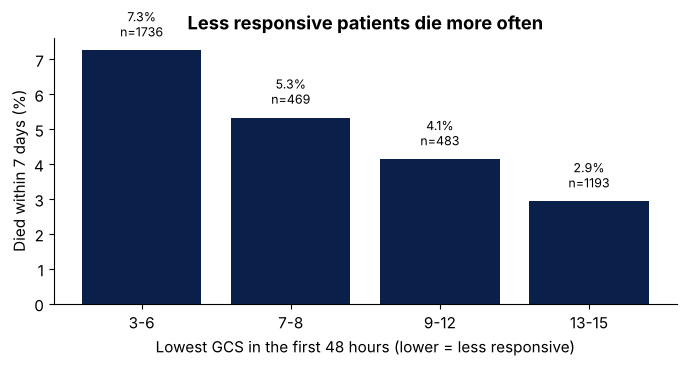

In [3]:
# A quick look at one strong signal: responsiveness (Glasgow Coma Scale, GCS, 3 = unresponsive, 15 = fully alert)
gcs = raw["GCS_lowest"]
bands = pd.cut(gcs, [2, 6, 8, 12, 15], labels=["3-6", "7-8", "9-12", "13-15"])
rate = pd.Series(y).groupby(bands).agg(["mean", "size"])
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.bar(rate.index.astype(str), 100 * rate["mean"], color=NAVY)
for i, (r, n_) in enumerate(zip(rate["mean"], rate["size"])):
    ax.text(i, 100 * r + 0.4, f"{100*r:.1f}%\nn={n_}", ha="center", fontsize=9)
ax.set_xlabel("Lowest GCS in the first 48 hours (lower = less responsive)")
ax.set_ylabel("Died within 7 days (%)")
ax.set_title("Less responsive patients die more often")
plt.tight_layout(); plt.show()

**What this shows:** death rates rise sharply as the lowest responsiveness score falls. This one measurement is associated with the outcome. The models below combine 116 inputs

# 3. One artificial neuron can be logistic regression

The neuron shown here does three things

1. Multiplies each input by a **weight**
2. Adds the results and a constant called the **bias**
3. Uses a **sigmoid** function to turn the total into a number between 0 and 1

A single neuron with this sigmoid output is the same mathematical model as logistic regression. Other types of neuron can use different output functions

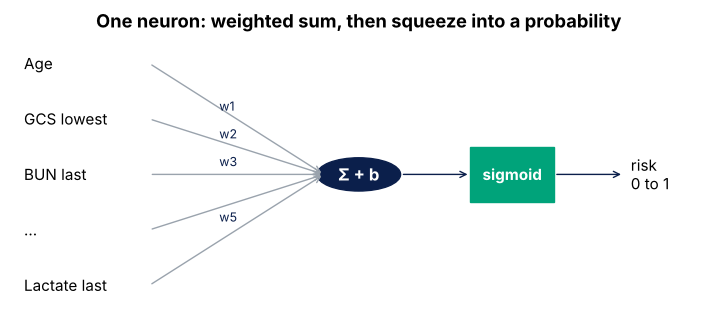

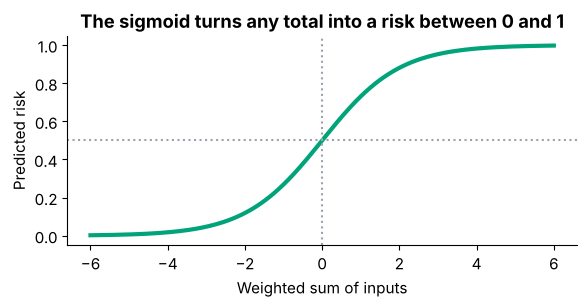

In [4]:
# Diagram of one neuron, drawn with matplotlib
fig, ax = plt.subplots(figsize=(9, 3.6)); ax.axis("off")
inputs = ["Age", "GCS lowest", "BUN last", "...", "Lactate last"]
for i, name in enumerate(inputs):
    yy = 0.9 - i * 0.2
    ax.text(0.02, yy, name, va="center", fontsize=11)
    ax.annotate("", xy=(0.45, 0.5), xytext=(0.2, yy), arrowprops=dict(arrowstyle="->", color=GREY))
    if name != "...":
        ax.text(0.3, (yy + 0.5) / 2 + 0.03, f"w{i+1}", fontsize=9, color=NAVY)
ax.add_patch(plt.Circle((0.5, 0.5), 0.06, color=NAVY))
ax.text(0.5, 0.5, "Σ + b", color="white", ha="center", va="center", fontsize=12, weight="bold")
ax.annotate("", xy=(0.66, 0.5), xytext=(0.56, 0.5), arrowprops=dict(arrowstyle="->", color=NAVY))
ax.add_patch(plt.Rectangle((0.66, 0.4), 0.12, 0.2, color=GREEN))
ax.text(0.72, 0.5, "sigmoid", color="white", ha="center", va="center", fontsize=11, weight="bold")
ax.annotate("", xy=(0.88, 0.5), xytext=(0.78, 0.5), arrowprops=dict(arrowstyle="->", color=NAVY))
ax.text(0.89, 0.5, "risk\n0 to 1", va="center", fontsize=11)
ax.set_title("One neuron: weighted sum, then squeeze into a probability"); plt.show()

z = np.linspace(-6, 6, 200)
plt.figure(figsize=(6, 3.2))
plt.plot(z, 1 / (1 + np.exp(-z)), color=GREEN, lw=3)
plt.axhline(0.5, color=GREY, ls=":"); plt.axvline(0, color=GREY, ls=":")
plt.xlabel("Weighted sum of inputs"); plt.ylabel("Predicted risk")
plt.title("The sigmoid turns any total into a risk between 0 and 1"); plt.tight_layout(); plt.show()

## 3.1 Train both and compare the weights

We fit this model with two software libraries

- Logistic regression in **scikit-learn**
- A single neuron with a sigmoid output in **PyTorch**

Both use the same scaled inputs and the same penalty on squared weight values, called **L2 regularisation**. We train both until further changes are very small. Their weights should then be nearly equal

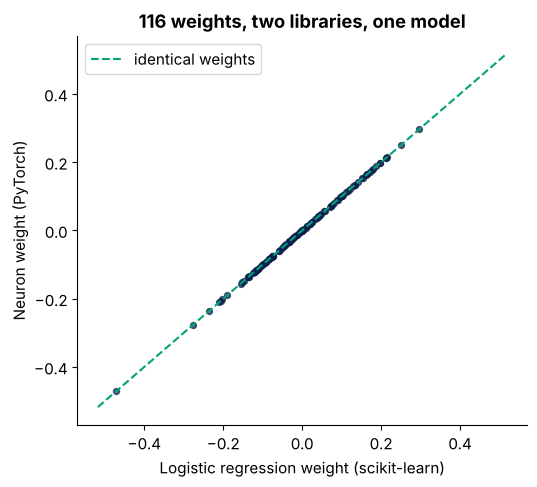

Largest weight difference: 0.0004
Test AUROC  logistic regression 0.864 | one neuron 0.864


In [5]:
# Same objective in both libraries: mean log-loss + (lam / 2) * sum(w^2)
lam = 0.01
n_tr = len(ytr)
logreg = LogisticRegression(C=1 / (lam * n_tr), max_iter=10_000, tol=1e-8).fit(Xtr, ytr)

neuron = nn.Linear(Xtr.shape[1], 1)                    # one neuron: 116 weights + 1 bias
opt = torch.optim.LBFGS(neuron.parameters(), lr=1, max_iter=500, tolerance_change=1e-12)
Xt, yt_ = torch.tensor(Xtr), torch.tensor(ytr, dtype=torch.float32)
bce = nn.BCEWithLogitsLoss()                           # sigmoid + log-loss in one stable step
def closure():
    opt.zero_grad()
    loss = bce(neuron(Xt).squeeze(1), yt_) + lam / 2 * (neuron.weight ** 2).sum()
    loss.backward(); return loss
for _ in range(5):
    opt.step(closure)

w_sk = logreg.coef_.ravel()
w_nn = neuron.weight.detach().numpy().ravel()
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.scatter(w_sk, w_nn, s=18, color=NAVY, alpha=0.7)
lim = np.abs(np.r_[w_sk, w_nn]).max() * 1.1
ax.plot([-lim, lim], [-lim, lim], color=GREEN, ls="--", label="identical weights")
ax.set_xlabel("Logistic regression weight (scikit-learn)"); ax.set_ylabel("Neuron weight (PyTorch)")
ax.set_title("116 weights, two libraries, one model"); ax.legend(); plt.tight_layout(); plt.show()

with torch.no_grad():
    p_neuron = torch.sigmoid(neuron(torch.tensor(Xte))).numpy().ravel()
p_logreg = logreg.predict_proba(Xte)[:, 1]
print(f"Largest weight difference: {np.abs(w_sk - w_nn).max():.4f}")
print(f"Test AUROC  logistic regression {roc_auc_score(yte, p_logreg):.3f} | one neuron {roc_auc_score(yte, p_neuron):.3f}")

**What this shows**

- The points lie almost on the diagonal: both implementations learned nearly identical weights. Both score 0.864 on the **area under the receiver operating characteristic curve (AUROC)**, which measures ranking: 0.5 means chance-level ranking and 1.0 means perfect ranking
- This network starts with a familiar model: logistic regression

> **Why we use matching settings:** we give both models the same inputs and training conditions so we can compare their weights fairly

## 3.2 Read the neuron like a clinician would

We rescale each input so that one step equals one **standard deviation (SD)**, a measure of how much that input varies among training patients. This lets us compare increases of a typical size across inputs

The chart turns each weight into an **odds multiplier**. A value of 1 means no change; 1.3 means 30% higher odds of death; 0.8 means 20% lower odds. This comparison changes one input while keeping all other inputs the same

Odds are not the same as probability: a 20% probability means 20 deaths for every 80 survivors, or odds of 1 to 4

**Labels in the charts:** `first`, `last`, `lowest` and `highest` refer to the first 48 h

| Label | Meaning |
|---|---|
| HCO3 | Bicarbonate, which helps control blood acidity |
| NIDiasABP | Non-invasive diastolic arterial blood pressure: pressure between heartbeats, measured with a cuff |
| HCT | Haematocrit: the share of blood volume made up of red blood cells |
| WBC | White blood cell count |
| HR | Heart rate |
| pH | A measure of acidity |
| ALT | Alanine aminotransferase, an enzyme used to assess liver injury |
| AST | Aspartate aminotransferase, an enzyme that can indicate liver or other tissue injury |

Source for liver-test terms: [MedlinePlus](https://medlineplus.gov/lab-tests/liver-function-tests/)

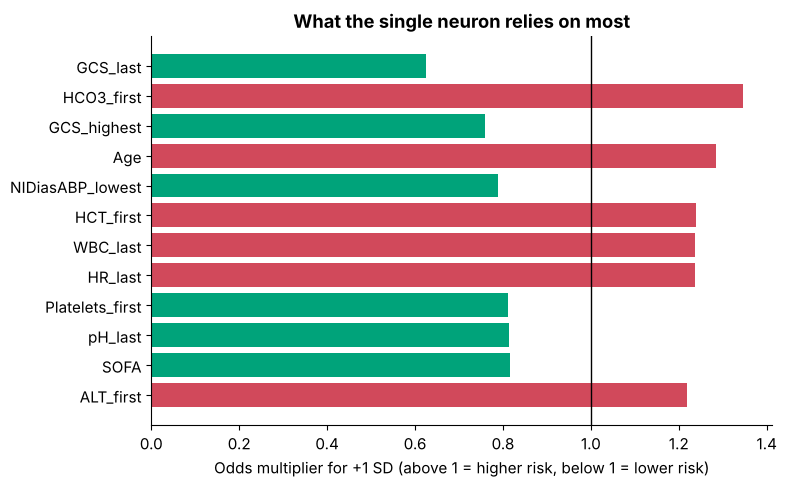

,weight,odds_multiplier
GCS_last,-0.471,0.62
HCO3_first,0.297,1.35
GCS_highest,-0.277,0.76
Age,0.251,1.29
NIDiasABP_lowest,-0.236,0.79
HCT_first,0.215,1.24
WBC_last,0.213,1.24
HR_last,0.212,1.24
Platelets_first,-0.210,0.81
pH_last,-0.206,0.81


In [6]:
# Top 12 weights of the single neuron, shown as odds multipliers per 1 SD increase
coef = pd.Series(w_nn, index=FEATURES)
top = coef.reindex(coef.abs().sort_values(ascending=False).index[:12])[::-1]
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top.index, np.exp(top.values), color=[RED if v > 0 else GREEN for v in top.values], left=0)
ax.axvline(1, color="black", lw=1)
ax.set_xlabel("Odds multiplier for +1 SD (above 1 = higher risk, below 1 = lower risk)")
ax.set_title("What the single neuron relies on most"); plt.tight_layout(); plt.show()
display(pd.DataFrame({"weight": top[::-1].round(3), "odds_multiplier": np.exp(top[::-1]).round(2)}))

**What this shows**

- For logistic regression, we can read how each input changes the prediction while keeping other inputs the same. This is **intrinsic interpretability**: the model's own formula provides the explanation
- Related inputs, such as the first and last values of the same measurement, share information. Their weights can point in opposite directions, so a weight needs to be read alongside the other inputs
- Example: a higher SOFA score means worse organ function, but here its odds multiplier is 0.82. Several other inputs describe the same organ problems. This overlap may explain the unexpected direction. It does not mean that more organ failure protects patients

> **Do not read a weight as a cause:** it describes an association within this model. It does not show that changing the input would change the patient's outcome

# 4. Add hidden neurons: the boundary can bend

With two inputs, logistic regression draws a **straight line** between predictions above and below a chosen risk threshold. A **hidden layer** adds neurons between the inputs and the output. Combining their signals lets the boundary bend

We use only two inputs so we can draw the predictions on a map

- Lowest Glasgow Coma Scale score: responsiveness
- Last blood urea nitrogen measurement: related to kidney function

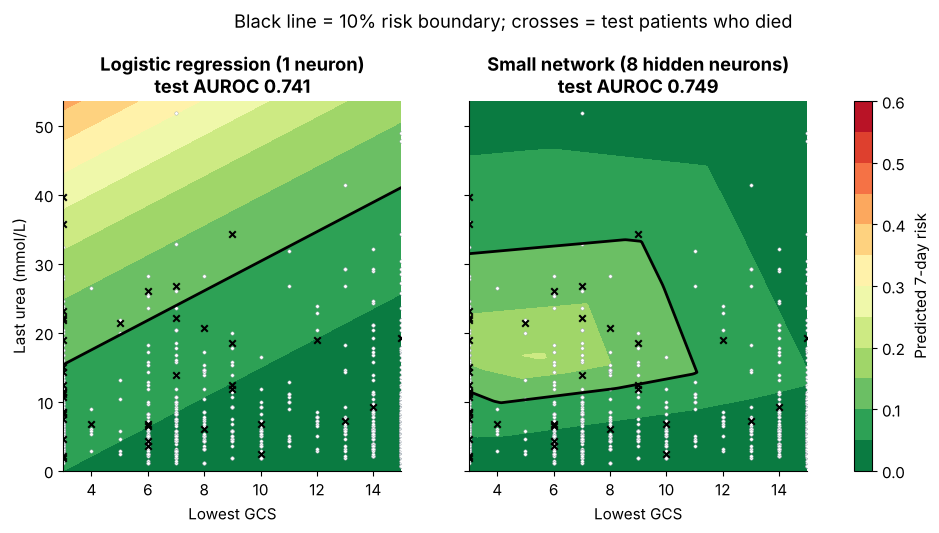

In [7]:
# Two-input models: logistic regression vs a small network with 8 hidden neurons
two = ["GCS_lowest", "BUN_last"]
cols2 = [FEATURES.index(c) for c in two]
X2tr, X2te = Xtr[:, cols2], Xte[:, cols2]

def train_net(model, Xa, ya, epochs=400, lr=0.01, wd=1e-4, pos_weight=None, Xv=None, yv=None, patience=None, seed=SEED):
    # Full-batch Adam training; optional early stopping on validation loss
    torch.manual_seed(seed)
    for m in model.modules():
        if hasattr(m, "reset_parameters"): m.reset_parameters()
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=wd)
    lossf = nn.BCEWithLogitsLoss(pos_weight=None if pos_weight is None else torch.tensor(pos_weight))
    Xa_t, ya_t = torch.tensor(Xa), torch.tensor(ya, dtype=torch.float32)
    hist, best, best_state, wait = [], np.inf, None, 0
    for ep in range(epochs):
        model.train(); opt.zero_grad()
        loss = lossf(model(Xa_t).squeeze(1), ya_t); loss.backward(); opt.step()
        rec = {"epoch": ep, "train_loss": loss.item()}
        if Xv is not None:
            model.eval()
            with torch.no_grad():
                vl = nn.BCEWithLogitsLoss()(model(torch.tensor(Xv)).squeeze(1), torch.tensor(yv, dtype=torch.float32)).item()
            rec["val_loss"] = vl
            if patience:
                if vl < best - 1e-5: best, best_state, wait = vl, {k: v.clone() for k, v in model.state_dict().items()}, 0
                else:
                    wait += 1
                    if wait >= patience: hist.append(rec); break
        hist.append(rec)
    if best_state is not None: model.load_state_dict(best_state)
    model.eval()
    return model, pd.DataFrame(hist)

def predict(model, Xa):
    with torch.no_grad():
        return torch.sigmoid(model(torch.tensor(Xa))).numpy().ravel()

lin2 = LogisticRegression().fit(X2tr, ytr)
torch.manual_seed(SEED)
net2 = nn.Sequential(nn.Linear(2, 8), nn.ReLU(), nn.Linear(8, 1))
net2, _ = train_net(net2, X2tr, ytr, epochs=1500, lr=0.02)

# Risk map over the grid of the two inputs (shown in original units)
def to_units(z, c):  # standard units -> clinical units (BUN shown as urea in mmol/L, the SI unit)
    j = FEATURES.index(c); v = z * scaler.scale_[j] + scaler.mean_[j]
    return v * 0.357 if c == "BUN_last" else v
def to_std(v, c):    # clinical units -> standard units
    j = FEATURES.index(c); return (v - scaler.mean_[j]) / scaler.scale_[j]
# Grid over realistic clinical ranges: GCS 3 to 15, BUN 0 to 150 mg/dL (0 to 54 mmol/L urea)
G1, G2 = np.meshgrid(to_std(np.linspace(3, 15, 200), two[0]), to_std(np.linspace(0, 150, 200), two[1]))
grid = np.c_[G1.ravel(), G2.ravel()].astype(np.float32)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharey=True)
for ax, (name, p) in zip(axes, [("Logistic regression (1 neuron)", lin2.predict_proba(grid)[:, 1]),
                                ("Small network (8 hidden neurons)", predict(net2, grid))]):
    cs = ax.contourf(to_units(G1, two[0]), to_units(G2, two[1]), p.reshape(G1.shape), levels=np.linspace(0, 0.6, 13), cmap="RdYlGn_r")
    ax.contour(to_units(G1, two[0]), to_units(G2, two[1]), p.reshape(G1.shape), levels=[0.10], colors="black", linewidths=2)
    dead = yte == 1
    ax.scatter(to_units(X2te[~dead, 0], two[0]), to_units(X2te[~dead, 1], two[1]), s=6, c="white", edgecolors=GREY, linewidths=0.3)
    ax.scatter(to_units(X2te[dead, 0], two[0]), to_units(X2te[dead, 1], two[1]), s=22, c="black", marker="x")
    auc = roc_auc_score(yte, lin2.predict_proba(X2te)[:, 1] if "Logistic" in name else predict(net2, X2te))
    ax.set_title(f"{name}\ntest AUROC {auc:.3f}"); ax.set_xlabel("Lowest GCS")
axes[0].set_ylabel("Last urea (mmol/L)")
fig.colorbar(cs, ax=axes, label="Predicted 7-day risk")
fig.suptitle("Black line = 10% risk boundary; crosses = test patients who died", y=1.07)
plt.show()

**What this shows**

- On the left, the line for 10% predicted risk is straight. Each input changes the model's internal score at a fixed rate
- On the right, the line bends. The effect of one input on that score can depend on the other input
- The AUROC scores are close: 0.741 and 0.749. A more flexible boundary does not guarantee better ranking
- Above about 36 mmol/L urea, the network predicts lower risk than at some moderate values. Few patients fall in this area. This pattern needs clinical review; the plot alone cannot establish why it appears

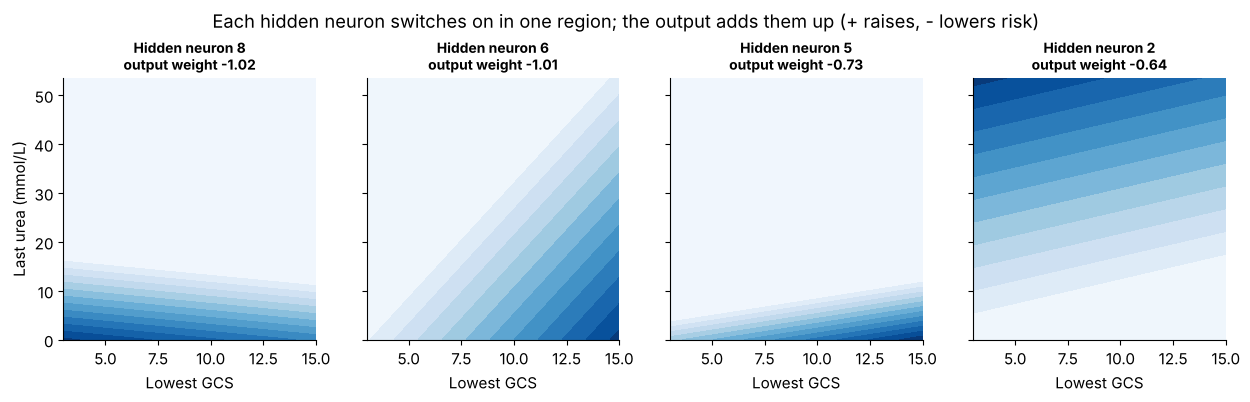

In [8]:
# Inside the small network: what each hidden neuron responds to
W1 = net2[0].weight.detach().numpy(); b1 = net2[0].bias.detach().numpy(); W2 = net2[2].weight.detach().numpy().ravel()
H = np.maximum(0, grid @ W1.T + b1)          # activation of each hidden neuron on the grid
order = np.argsort(-np.abs(W2))[:4]
fig, axes = plt.subplots(1, 4, figsize=(15, 3.4), sharey=True)
for ax, k in zip(axes, order):
    ax.contourf(to_units(G1, two[0]), to_units(G2, two[1]), H[:, k].reshape(G1.shape), levels=12, cmap="Blues")
    ax.set_title(f"Hidden neuron {k+1}\noutput weight {W2[k]:+.2f}", fontsize=10); ax.set_xlabel("Lowest GCS")
axes[0].set_ylabel("Last urea (mmol/L)")
fig.suptitle("Each hidden neuron switches on in one region; the output adds them up (+ raises, - lowers risk)", y=1.08)
plt.show()

**What this shows:** each hidden neuron is inactive on one side of a line and increases its signal on the other side. The output combines these signals to form the bent boundary. These hidden neurons use a different function from the sigmoid output shown earlier. With 2 inputs and 8 hidden neurons we can still inspect the pattern; next we add more

# 5. A full network on all 116 inputs

We now build a network for tabular data: data arranged in rows and columns

- **Structure:** 116 inputs, two hidden layers with 32 and 16 neurons, and one output
- **Rectified linear unit (ReLU):** a hidden neuron outputs zero when its weighted total is negative and passes the total through when it is positive
- **Dropout:** during each training step, randomly set 20% of the hidden signals to zero. This can reduce overfitting, where the model learns patterns specific to its training data
- **Early stopping:** keep the model with the lowest validation error and stop training after a set period without improvement

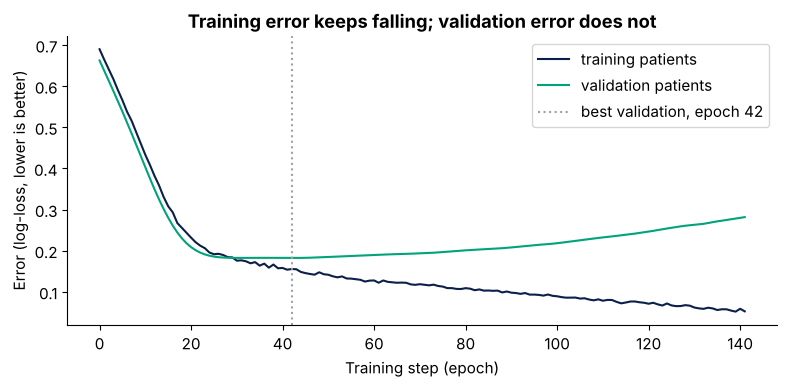

Parameters: single neuron 117 | network 4,289
Test AUROC: logistic regression 0.864 | network 0.842


In [9]:
def make_mlp(n_in, seed=SEED):
    torch.manual_seed(seed)
    return nn.Sequential(nn.Linear(n_in, 32), nn.ReLU(), nn.Dropout(0.2),
                         nn.Linear(32, 16), nn.ReLU(), nn.Dropout(0.2),
                         nn.Linear(16, 1))

mlp = make_mlp(Xtr.shape[1])
n_params = sum(p.numel() for p in mlp.parameters())
mlp, hist = train_net(mlp, Xtr, ytr, epochs=1500, lr=0.003, wd=1e-3, Xv=Xva, yv=yva, patience=100)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(hist.epoch, hist.train_loss, color=NAVY, label="training patients")
ax.plot(hist.epoch, hist.val_loss, color=GREEN, label="validation patients")
best_ep = int(hist.val_loss.idxmin())
ax.axvline(best_ep, color=GREY, ls=":", label=f"best validation, epoch {best_ep}")
ax.set_xlabel("Training step (epoch)"); ax.set_ylabel("Error (log-loss, lower is better)")
ax.set_title("Training error keeps falling; validation error does not"); ax.legend(); plt.tight_layout(); plt.show()

p_mlp = predict(mlp, Xte)
print(f"Parameters: single neuron {Xtr.shape[1] + 1} | network {n_params:,}")
print(f"Test AUROC: logistic regression {roc_auc_score(yte, p_logreg):.3f} | network {roc_auc_score(yte, p_mlp):.3f}")

**What this shows**

- The network learns 4,289 parameters, meaning weights and biases, compared with 117 for the single neuron. That is about 37 times as many, from the same 2,364 training patients
- Training error falls while validation error eventually rises. This is a sign of overfitting: further training is no longer helping on validation patients. Early stopping keeps an earlier version
- The network's test AUROC is lower than logistic regression's: 0.842 against 0.864. Session 2 checks how uncertain such differences are

## 5.1 Try to read the network

Every number inside the network is visible. Here are all the weights of the first layer: one row per input, one column per hidden neuron

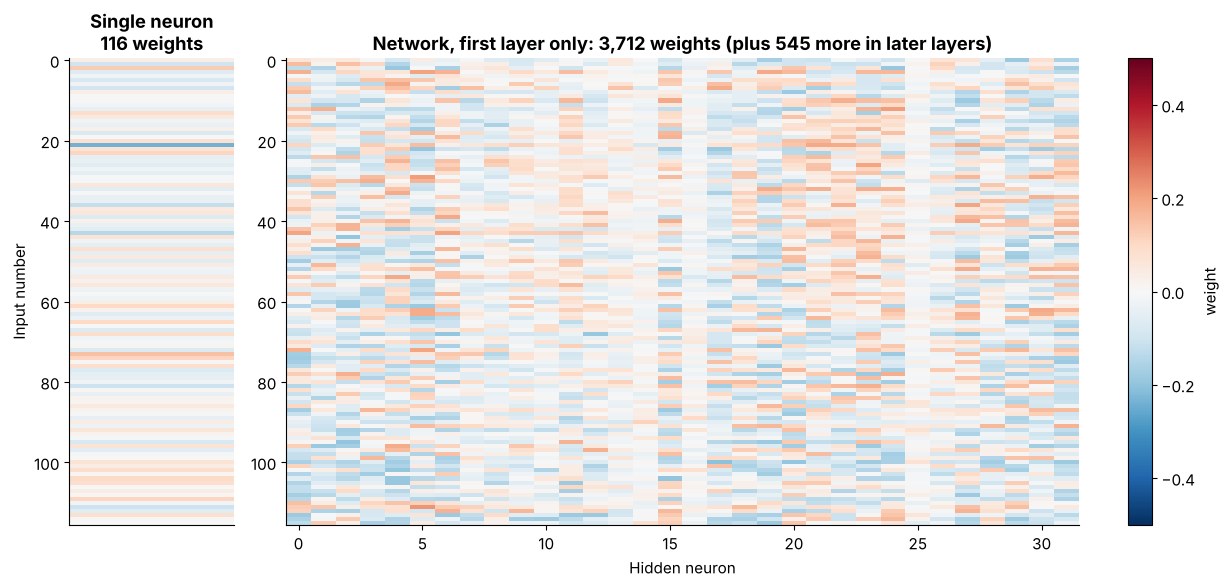

In [10]:
W = mlp[0].weight.detach().numpy().T          # 116 inputs x 32 hidden neurons
fig, axes = plt.subplots(1, 2, figsize=(13, 6), gridspec_kw={"width_ratios": [1, 6]})
axes[0].imshow(w_nn.reshape(-1, 1), aspect="auto", cmap="RdBu_r", vmin=-1, vmax=1)
axes[0].set_title("Single neuron\n116 weights"); axes[0].set_xticks([]); axes[0].set_ylabel("Input number")
im = axes[1].imshow(W, aspect="auto", cmap="RdBu_r", vmin=-0.5, vmax=0.5)
axes[1].set_title(f"Network, first layer only: {W.size:,} weights (plus {n_params - W.size - 32:,} more in later layers)")
axes[1].set_xlabel("Hidden neuron")
fig.colorbar(im, ax=axes[1], label="weight"); plt.tight_layout(); plt.show()

**What this shows**

- On the left, logistic regression has one weight per input, which we can read directly
- On the right, each input connects to many hidden neurons. Later layers combine their signals again, so one weight cannot describe the overall effect of an input such as lactate

We can inspect every calculation, but it is much harder to turn all those calculations into a short explanation of one prediction

## 5.2 One patient, two explanations

Choose one test patient who died. How can we explain the two predictions?

- **Logistic regression:** each input contributes `weight x scaled value` to the total before the sigmoid. Adding every contribution and the bias reconstructs the prediction exactly
- **Network:** we test one input at a time by replacing it with its training median, the middle value among training patients. We record how much the prediction changes. This is an **occlusion test**. It answers a specific question about the model rather than providing a complete explanation

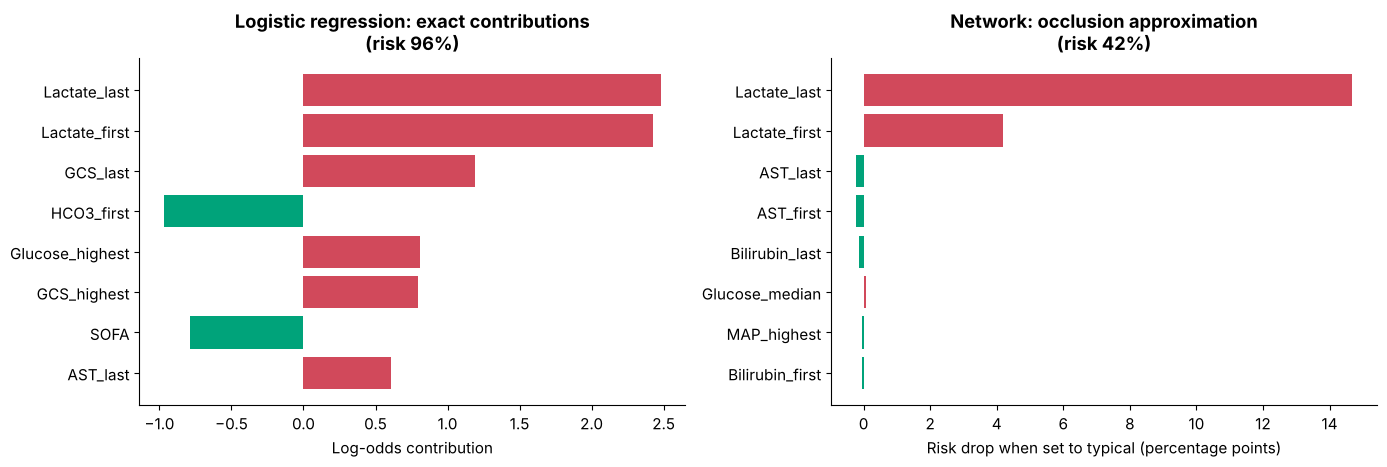

Inputs in both top-8 lists: 3 of 8 -> ['AST_last', 'Lactate_first', 'Lactate_last']


In [11]:
# Patient with the highest network risk among test deaths
i = int(np.argmax(np.where(yte == 1, p_mlp, -1)))
x = Xte[i:i + 1]
contrib_lr = pd.Series(logreg.coef_.ravel() * x.ravel(), index=FEATURES)   # exact log-odds contributions

median_std = scaler.transform(imputer.statistics_.reshape(1, -1)).astype(np.float32).ravel()
base = predict(mlp, x)[0]
occl = {}
for j, f in enumerate(FEATURES):
    xx = x.copy(); xx[0, j] = median_std[j]
    occl[f] = base - predict(mlp, xx)[0]                                     # risk drop when input j is made typical
occl = pd.Series(occl)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
t1 = contrib_lr.reindex(contrib_lr.abs().sort_values(ascending=False).index[:8])[::-1]
axes[0].barh(t1.index, t1.values, color=[RED if v > 0 else GREEN for v in t1.values])
axes[0].set_title(f"Logistic regression: exact contributions\n(risk {logreg.predict_proba(x)[0,1]:.0%})"); axes[0].set_xlabel("Log-odds contribution")
t2 = occl.reindex(occl.abs().sort_values(ascending=False).index[:8])[::-1]
axes[1].barh(t2.index, 100 * t2.values, color=[RED if v > 0 else GREEN for v in t2.values])
axes[1].set_title(f"Network: occlusion approximation\n(risk {base:.0%})"); axes[1].set_xlabel("Risk drop when set to typical (percentage points)")
plt.tight_layout(); plt.show()
overlap = set(t1.index) & set(t2.index)
print(f"Inputs in both top-8 lists: {len(overlap)} of 8 -> {sorted(overlap)}")

**What this shows**

- Only 3 inputs appear in both top-8 lists. The models assign different importance to the same patient's measurements
- For logistic regression, all input contributions plus the bias add up to the total before the sigmoid, called the **log-odds**. The chart shows only the largest contributions
- For the network, each bar shows what changes when one input is replaced by its training median. These changes need not add up to the prediction, and they do not fully describe how inputs work together
- Replacing one input while leaving related inputs unchanged can create an unusual combination. Results also depend on the replacement value

> **Check the explanation method:** a convincing chart can still give an incomplete or misleading account. Session 4 tests explanation maps

# 6. Does retraining change which patients get an alert?

We train both **logistic regression** and the **neural network** five times, using seeds 0 to 4. Each model keeps its existing settings. Both use the same training and test patients, the same prepared features and a 10% alert threshold

For the network, the seed changes the starting weights and dropout pattern. Logistic regression uses the same fitting method as before (`lbfgs`), which does not use the random seed. We include it as a comparison and check whether its predictions stay the same

This tests variation from training randomness. It does not test what happens when training patients, features or model settings change

Source for the logistic regression seed setting: [Scikit-learn documentation](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html)

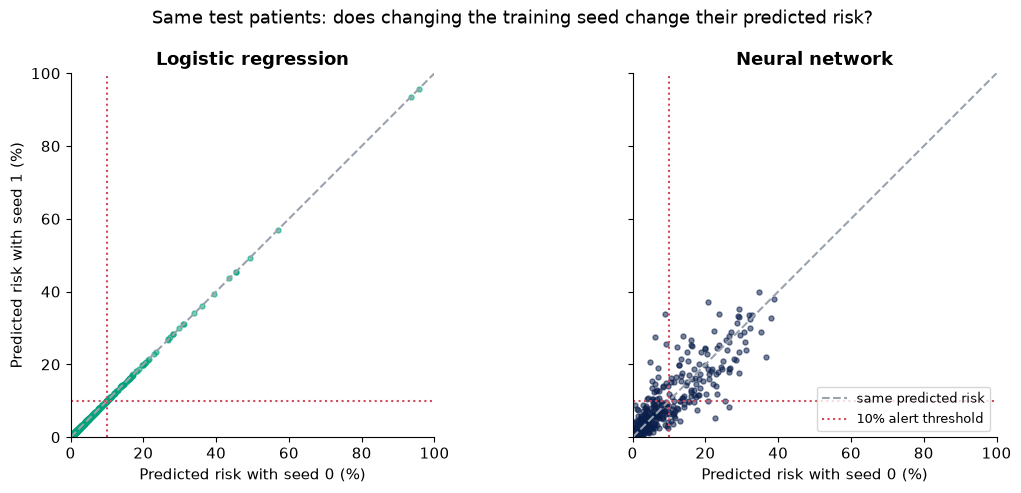

Five seeds per model; same 788 test patients; alert at predicted risk of at least 10%


,Logistic regression,Neural network
Lowest ranking score (AUROC),0.864,0.839
Highest ranking score (AUROC),0.864,0.851
Test patients,788.000,788.000
Patients alerted by at least one run,89.000,183.000
Patients alerted by all five runs,89.000,77.000
Patients whose alert changes across runs,0.000,106.000
Patients whose alert changes (% of all test patients),0.000,13.452
Largest risk change across runs (percentage points),0.000,33.654
Mean risk change across runs (percentage points),0.000,3.705


The plots compare seeds 0 and 1; the table compares all five seeds


In [12]:
# Same patients, model settings and alert threshold; vary only the training seed
from sklearn.base import clone

seeds = range(5)
network_runs, logistic_runs = {}, {}
for s in seeds:
    m, _ = train_net(make_mlp(Xtr.shape[1], seed=s), Xtr, ytr, epochs=1500, lr=0.003, wd=1e-3,
                     Xv=Xva, yv=yva, patience=100, seed=s)
    network_runs[f"seed {s}"] = predict(m, Xte)

    # Clone the earlier logistic regression, preserving its penalty and fitting settings
    lr_run = clone(logreg).set_params(random_state=s)
    lr_run.fit(Xtr, ytr)
    logistic_runs[f"seed {s}"] = lr_run.predict_proba(Xte)[:, 1]

R = pd.DataFrame(network_runs)
L = pd.DataFrame(logistic_runs)
prediction_runs = {"Logistic regression": L, "Neural network": R}
threshold = 0.10
stability_results = {}
for name, predictions in prediction_runs.items():
    scores = predictions.apply(lambda p: roc_auc_score(yte, p))
    alerts = predictions >= threshold
    changed = alerts.any(axis=1) & ~alerts.all(axis=1)
    spread = predictions.max(axis=1) - predictions.min(axis=1)
    stability_results[name] = {
        "Lowest ranking score (AUROC)": scores.min(),
        "Highest ranking score (AUROC)": scores.max(),
        "Test patients": len(yte),
        "Patients alerted by at least one run": int(alerts.any(axis=1).sum()),
        "Patients alerted by all five runs": int(alerts.all(axis=1).sum()),
        "Patients whose alert changes across runs": int(changed.sum()),
        "Patients whose alert changes (% of all test patients)": 100 * changed.mean(),
        "Largest risk change across runs (percentage points)": 100 * spread.max(),
        "Mean risk change across runs (percentage points)": 100 * spread.mean(),
    }

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
for ax, (name, predictions), colour in zip(axes, prediction_runs.items(), [GREEN, NAVY]):
    ax.scatter(100 * predictions["seed 0"], 100 * predictions["seed 1"],
               s=13, alpha=0.55, color=colour)
    ax.plot([0, 100], [0, 100], color=GREY, ls="--", label="same predicted risk")
    ax.axvline(10, color=RED, ls=":", label="10% alert threshold")
    ax.axhline(10, color=RED, ls=":")
    ax.set_xlim(0, 100); ax.set_ylim(0, 100); ax.set_aspect("equal")
    ax.set_xlabel("Predicted risk with seed 0 (%)")
    ax.set_title(name)
axes[0].set_ylabel("Predicted risk with seed 1 (%)")
axes[1].legend(fontsize=9, loc="lower right")
fig.suptitle("Same test patients: does changing the training seed change their predicted risk?")
plt.tight_layout(); plt.show()

print("Five seeds per model; same 788 test patients; alert at predicted risk of at least 10%")
display(pd.DataFrame(stability_results).round(3))
print("The plots compare seeds 0 and 1; the table compares all five seeds")

# Preserve the original network summaries for any follow-up classroom inspection
aucs = R.apply(lambda p: roc_auc_score(yte, p))
flags = R >= threshold
changes = flags.any(axis=1) & ~flags.all(axis=1)


**What this shows**

- **Logistic regression:** all five fits give identical predicted risks and alert decisions. The ranking score is 0.864 in every run, and the same 89 patients receive an alert
- **Neural network:** ranking scores range from 0.839 to 0.851. Of 788 test patients, 106 (13.5%) receive an alert in some runs but not others
- For the network, 183 patients receive an alert from at least one run, but only 77 receive one from all five. These counts describe agreement across runs, not the number of deaths prevented

**Why the difference?** This logistic regression fitting method does not use the seed, so changing it leaves the fit unchanged. The network uses random starting weights and dropout, so different seeds can lead to different predictions. A small risk change can cross the 10% alert threshold even when overall ranking changes little

This is an example of the **Rashomon effect**: several models can perform similarly overall. When they give different individual predictions, this is called **predictive multiplicity**. It also occurs in other model types ([Marx et al., 2020](https://proceedings.mlr.press/v119/marx20a.html))

> **Scope of the result:** the network is more sensitive to the training seed than this logistic regression fit, on these fixed data. We have not tested a random forest here, or tested either model on different training samples

> **Practical action:** compare individual prediction and alert stability alongside overall scores, and record which fitted model produced each alert

# 7. Takeaways

**Key insights**

- A single neuron with a sigmoid output is logistic regression
- Hidden layers let the prediction boundary bend and let inputs work together in more complex ways
- Access to every weight does not guarantee a short, clear explanation of a prediction
- With these fixed data, changing the seed changes network alerts but leaves this logistic regression fit unchanged

**Common pitfalls**

- Calling a model understandable because its code and weights are available
- Treating an explanation chart as a complete account of a prediction
- Reporting only the best training run
- Treating weights as evidence of cause and effect

**What this means for healthcare decision makers**

| Stakeholder | Question to ask before using a neural network |
|---|---|
| Clinician | What can I check before acting on an alert? |
| Patient | Why was I flagged, and how can I ask for a review? |
| Hospital manager | Does the model improve care enough to justify the extra checking and monitoring? |
| Regulator or auditor | Which model version made the prediction, and how stable are its decisions? |

**Next session:** does this network improve on Cox and random forest models once we consider uncertainty and workload?

**Check your understanding**

1. Why did the single neuron and logistic regression learn nearly equal weights?
2. What can the bent boundary represent that the straight line cannot?
3. Why does changing the seed affect the network but not this logistic regression fit? Does this test show what happens when training patients change?